##**ACA 1 – Aprendizaje Automático**

---

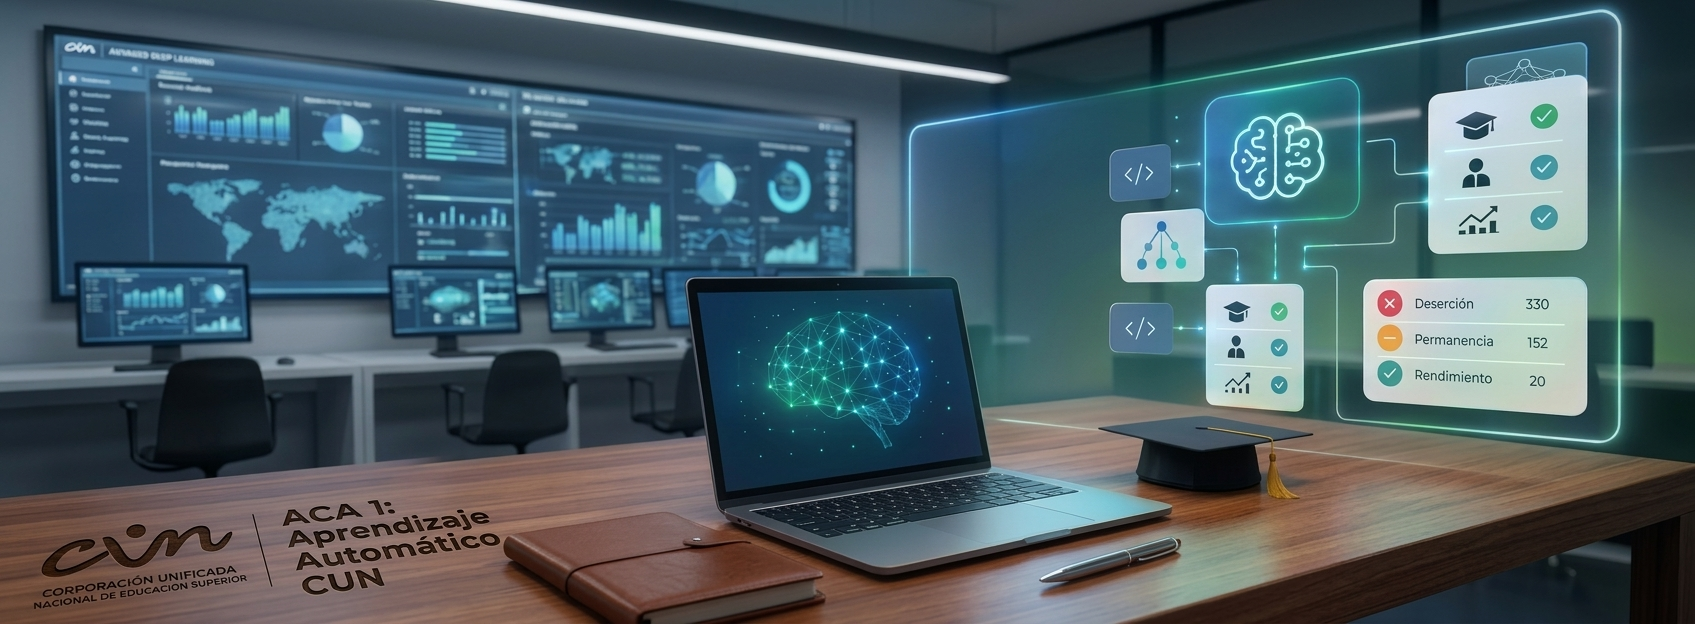

##**Analítica académica y prevención de la deserción en educación superior**
**Pilar:** Educación  
**Dataset:** *Predict Students Dropout and Academic Success* (UCI Machine Learning Repository)  
**Problema de ML:** clasificación multiclase (`Dropout`, `Enrolled`, `Graduate`)  

### **Objetivo del proyecto**

Desarrollar una solución integral de *Machine Learning* clásico que transforme datos académicos, administrativos y sociodemográficos en una predicción reproducible del resultado académico del estudiante, desde la auditoría y preparación de los datos hasta la evaluación cuantitativa y el despliegue en Streamlit.

### **Pregunta orientadora**
¿Cómo transformar información académica y administrativa disponible durante la trayectoria inicial del estudiante en una estimación útil del riesgo de deserción, permanencia o graduación, mediante algoritmos clásicos de aprendizaje automático y una interfaz interactiva de apoyo a la decisión?

##**Integrantes**

>- Johnny Alirio Blanquicett Cardona.
>- Miguel Orlando Mora Moreno.
>- Ramón Benjamín Buelvas Sierra.
>- Rubby Yesenia Parrado Rodríguez.

===========================================================================================================
### 1. Importación de librerías
---

Se importan las librerías necesarias para la manipulación y análisis de datos, la visualización, el entrenamiento y la evaluación de modelos de Machine Learning, así como la gestión de archivos y la configuración del entorno de trabajo.

Se establece una semilla aleatoria `(RANDOM_STATE = 42)` para favorecer la reproducibilidad de los experimentos y se configuran las opciones de visualización.



In [139]:
# #Importación de librerias

import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    log_loss,
    roc_auc_score
)

from sklearn.utils.validation import check_is_fitted


warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

print("✅ Librerías cargadas correctamente")
print("Versión de pandas:", pd.__version__)
print("Versión de scikit-learn:"), print(sklearn.__version__)

✅ Librerías cargadas correctamente
Versión de pandas: 2.2.3
Versión de scikit-learn:
1.6.1


(None, None)

===========================================================================================================
###2. Ingeniería de características
---

Se crea el archivo `feature_engineering.py`, que contiene la función `add_engineered_features()` para generar cinco características derivadas de las variables académicas originales: promedio de notas, cambio de notas entre semestres, tasas de aprobación de cada semestre y variación en las unidades aprobadas.

Estas características complementan los datos originales y se utilizan posteriormente durante el entrenamiento y la predicción del modelo.

In [140]:
#Crear feature_engineering.py

%%writefile feature_engineering.py

def add_engineered_features(X_raw):
    X = X_raw.copy()

    # Columnas académicas originales
    grade_1 = "Curricular units 1st sem (grade)"
    grade_2 = "Curricular units 2nd sem (grade)"

    approved_1 = "Curricular units 1st sem (approved)"
    approved_2 = "Curricular units 2nd sem (approved)"

    evaluations_1 = "Curricular units 1st sem (evaluations)"
    evaluations_2 = "Curricular units 2nd sem (evaluations)"

    # Promedio de notas de ambos semestres
    if grade_1 in X.columns and grade_2 in X.columns:
        X["Mean semester grade"] = X[
            [grade_1, grade_2]
        ].mean(axis=1)

        X["Grade change"] = X[grade_2] - X[grade_1]

    # Tasa de aprobación del primer semestre
    if approved_1 in X.columns and evaluations_1 in X.columns:
        X["Approval rate 1"] = (
            X[approved_1]
            / X[evaluations_1].replace(0, float("nan"))
        )

    # Tasa de aprobación del segundo semestre
    if approved_2 in X.columns and evaluations_2 in X.columns:
        X["Approval rate 2"] = (
            X[approved_2]
            / X[evaluations_2].replace(0, float("nan"))
        )

    # Cambio de unidades aprobadas entre semestres
    if approved_1 in X.columns and approved_2 in X.columns:
        X["Approved change"] = X[approved_2] - X[approved_1]

    return X

Overwriting feature_engineering.py


===========================================================================================================
###3. Importación de la función de ingeniería de características
---

Se importa la función `add_engineered_features()` desde el archivo feature_engineering.py para utilizarla en las siguientes etapas del análisis, el entrenamiento y la predicción del modelo.

In [141]:
# Importar la función para usar

from feature_engineering import add_engineered_features

print("✅ feature_engineering.py creado e importado")

✅ feature_engineering.py creado e importado


===========================================================================================================
###4. Carga del conjunto de datos
---

Se establece la conexión con Google Drive para acceder al conjunto de datos data.csv. Se verifica la existencia del archivo y se realiza su lectura utilizando el `punto y coma (;)` como separador.

Posteriormente, se eliminan los espacios innecesarios de los nombres de las columnas y se visualizan las primeras cinco filas para comprobar la carga correcta de la información.

In [142]:
# Cargar el dataset
from google.colab import drive

drive.mount("/content/drive")

ruta = Path(
    "/content/drive/MyDrive/Aprendizaje_Automatico/ACA1/data.csv"
)

if not ruta.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {ruta}"
    )

# El dataset UCI utiliza normalmente punto y coma
df = pd.read_csv(ruta, sep=";")

# Limpiar espacios en los nombres de las columnas
df.columns = df.columns.str.strip()

print("\n✅ Dataset cargado correctamente")
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("\nPrimeras 5 filas:")

display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✅ Dataset cargado correctamente
Filas: 4424
Columnas: 37

Primeras 5 filas:


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


###**Visualización de la variable objetivo**

---



Se representa la distribución de los estudiantes según su estado académico (Target), mediante un gráfico de barras que muestra la cantidad y el porcentaje de registros correspondientes a cada categoría: Graduate, Dropout y Enrolled.

Esta visualización permite identificar la frecuencia de cada resultado académico y observar cómo se distribuyen las clases dentro del conjunto de datos. Además, facilita reconocer posibles diferencias en la representación de las categorías, aspecto relevante para las posteriores etapas de entrenamiento y evaluación de los modelos de clasificación.

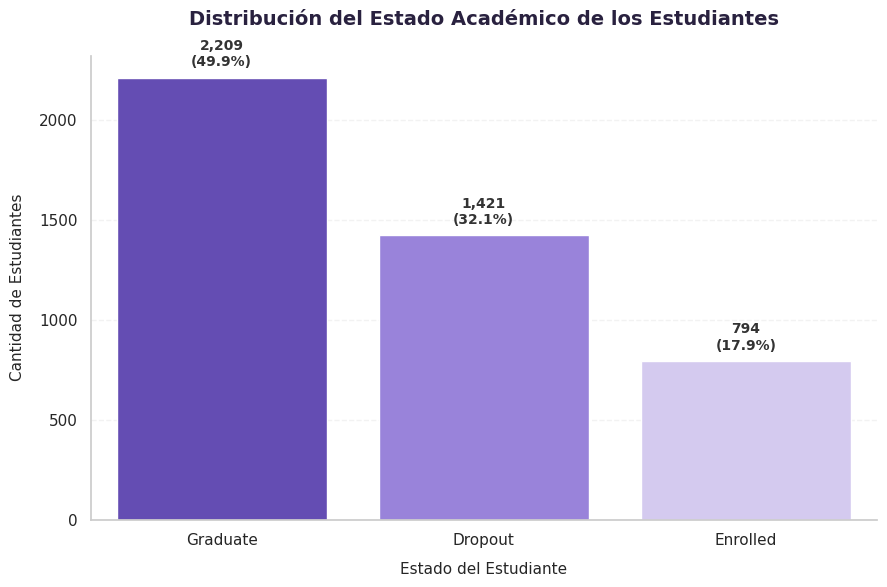

In [143]:
# Visualización de la variable objetivo

import matplotlib.pyplot as plt
import seaborn as sns

# Paleta colores
colores = {
    'Graduate': '#5B3CC4',
    'Dropout': '#9275E8',
    'Enrolled': '#D1C4F5'
}

orden_target = ['Graduate', 'Dropout', 'Enrolled']

plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=df,
    x='Target',
    hue='Target',
    palette=colores,
    order=orden_target,
    hue_order=orden_target,
    legend=False
)

# Calcular el total de registros con Target válido
total = df['Target'].notna().sum()

# Mostrar cantidad y porcentaje sobre cada barra
for p in ax.patches:
    altura = p.get_height()

    if altura > 0:
        porcentaje = (altura / total) * 100
        etiqueta = f'{int(altura):,}\n({porcentaje:.1f}%)'

        ax.annotate(
            etiqueta,
            (p.get_x() + p.get_width() / 2, altura),
            ha='center',
            va='bottom',
            xytext=(0, 6),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            color='#333333'
        )

# Título y etiquetas
ax.set_title(
    'Distribución del Estado Académico de los Estudiantes',
    fontsize=14,
    fontweight='bold',
    color='#29213F',
    pad=22
)

ax.set_xlabel('Estado del Estudiante', fontsize=11, labelpad=10)
ax.set_ylabel('Cantidad de Estudiantes', fontsize=11, labelpad=10)

# Estética y espacio superior
sns.despine()
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.set_ylim(top=ax.get_ylim()[1] * 1.0)

plt.tight_layout()
plt.savefig('target_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

###**Análisis de impacto socioeconómico y académico**

---

Se analiza la relación entre dos variables relacionadas con la situación socioeconómica de los estudiantes y su resultado académico (Target).

La primera gráfica compara el estado de pago de la matrícula (Tuition fees up to date) con las categorías de resultado académico, mientras que la segunda relaciona la condición de beneficiario de una beca (Scholarship holder) con dichas categorías.

Mediante gráficos de barras agrupadas se representa la cantidad de estudiantes en cada combinación de categorías. Esta comparación permite explorar cómo se distribuyen los resultados académicos según el estado de pago de matrícula y la condición de becado, e identificar posibles patrones o diferencias entre los grupos.

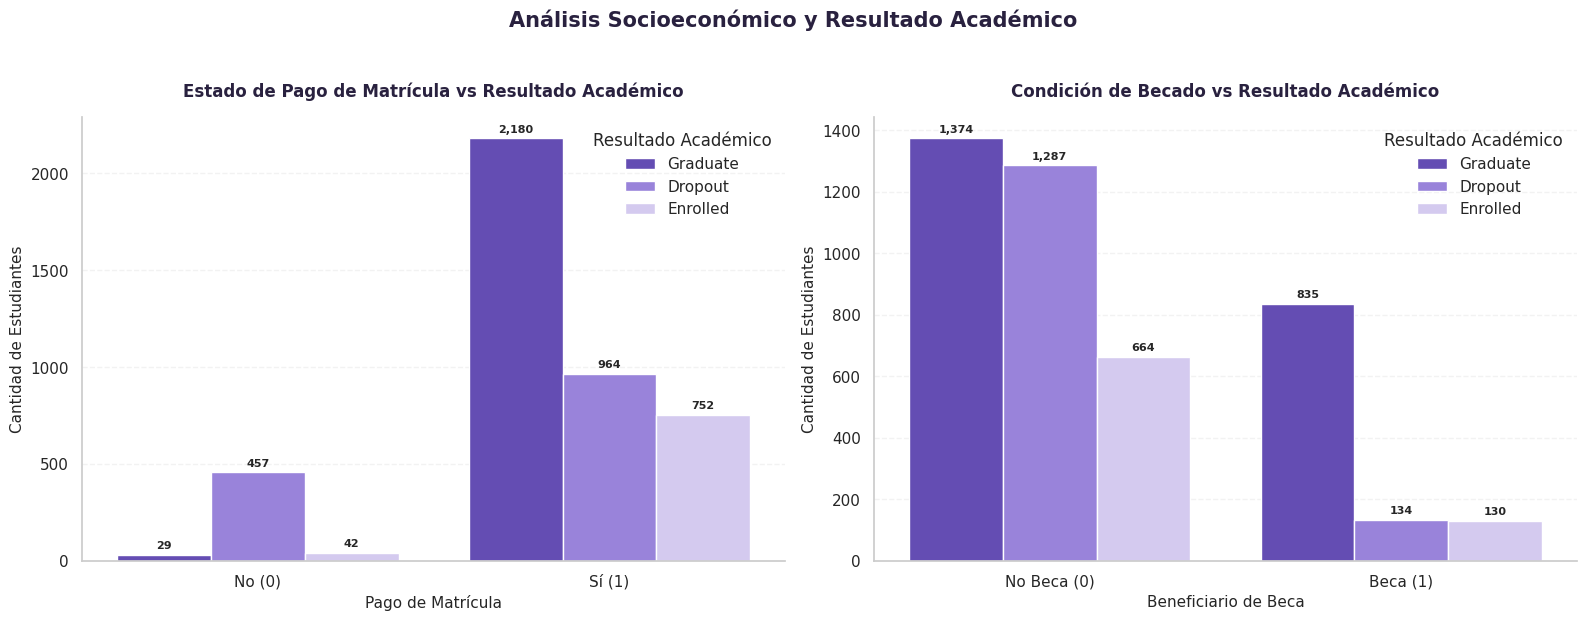

In [144]:
#Análisis de impacto socioeconómico y académico

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Orden de los resultados académicos
orden_target = ['Graduate', 'Dropout', 'Enrolled']

# Paleta colores
colores_target = {
    'Graduate': '#5B3CC4',
    'Dropout': '#9275E8',
    'Enrolled': '#D1C4F5'
}

# Estado de pago de matrícula vs resultado académico
sns.countplot(
    data=df,
    x='Tuition fees up to date',
    hue='Target',
    hue_order=orden_target,
    palette=colores_target,
    ax=axes[0]
)

axes[0].set_title(
    'Estado de Pago de Matrícula vs Resultado Académico',
    fontsize=12,
    fontweight='bold',
    color='#29213F',
    pad=15
)

axes[0].set_xlabel('Pago de Matrícula', fontsize=11)
axes[0].set_ylabel('Cantidad de Estudiantes', fontsize=11)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No (0)', 'Sí (1)'])

# Becas vs resultado académico
sns.countplot(
    data=df,
    x='Scholarship holder',
    hue='Target',
    hue_order=orden_target,
    palette=colores_target,
    ax=axes[1]
)

axes[1].set_title(
    'Condición de Becado vs Resultado Académico',
    fontsize=12,
    fontweight='bold',
    color='#29213F',
    pad=15
)

axes[1].set_xlabel('Beneficiario de Beca', fontsize=11)
axes[1].set_ylabel('Cantidad de Estudiantes', fontsize=11)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['No Beca (0)', 'Beca (1)'])

# Agregar cantidades sobre las barras
for ax in axes:
    for container in ax.containers:
        etiquetas = [
            f'{int(barra.get_height()):,}' if barra.get_height() > 0 else ''
            for barra in container
        ]

        ax.bar_label(
            container,
            labels=etiquetas,
            padding=3,
            fontsize=8,
            fontweight='bold'
        )

    sns.despine(ax=ax)
    ax.grid(axis='y', linestyle='--', alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(title='Resultado Académico', frameon=False)

fig.suptitle(
    'Análisis Socioeconómico y Resultado Académico',
    fontsize=15,
    fontweight='bold',
    color='#29213F',
    y=1.03
)

plt.tight_layout()
plt.savefig('eda_socioeconomic.png', dpi=300, bbox_inches='tight')
plt.show()

===========================================================================================================
###5. Validación y exploración inicial de los datos
---

Se verifica la existencia de la variable objetivo `Target` y se realiza una revisión inicial de la calidad del conjunto de datos mediante la identificación de valores faltantes y registros duplicados.

Además, se analiza la distribución de las clases de la variable objetivo, expresada en cantidades y porcentajes, y se consultan los tipos de datos de las columnas.

In [145]:
if "Target" not in df.columns:
    raise ValueError(
        "No se encontró la columna 'Target' en el dataset."
    )

print("Valores faltantes:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

print("\nDistribución de la variable objetivo:")
display(
    pd.DataFrame({
        "Cantidad": df["Target"].value_counts(),
        "Porcentaje (%)": (
            df["Target"].value_counts(normalize=True) * 100
        ).round(2)
    })
)

print("\nTipos de datos:")
display(df.dtypes.to_frame("Tipo de dato"))

Valores faltantes: 0
Filas duplicadas: 0

Distribución de la variable objetivo:


,Cantidad,Porcentaje (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95



Tipos de datos:


,Tipo de dato
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64


###**Análisis de los resultados**

---

La revisión inicial muestra que el conjunto de datos contiene 4.424 registros y 37 columnas, sin valores faltantes ni filas duplicadas. Esto permite continuar con el análisis sin requerir una limpieza por estos dos aspectos.

En cuanto a la variable objetivo, se identifican tres categorías:

Graduate: 2.209 registros (49,93 %).

Dropout: 1.421 registros (32,12 %).

Enrolled: 794 registros (17,95 %).

La distribución evidencia una mayor representación de estudiantes graduados y una menor proporción de estudiantes que continúan matriculados. Por tanto, las clases presentan una distribución desigual, aspecto que deberá considerarse durante el entrenamiento y la evaluación de los modelos.

Respecto a los tipos de datos, se observan variables numéricas de tipo entero (int64), variables decimales (float64) y la variable objetivo Target, de tipo texto (object). Aunque varias variables enteras representan categorías codificadas, será necesario diferenciarlas de las variables numéricas durante el preprocesamiento.

===========================================================================================================
###6. Preparación de variables y generación de características
---

Se separan las variables predictoras originales de la variable objetivo Target. Posteriormente, se aplica la función de ingeniería de características para generar cinco variables derivadas a partir de la información académica de ambos semestres.

Finalmente, se identifican las variables nuevas, se contabilizan los predictores originales y derivados, y se obtiene un resumen estadístico de las características generadas.

In [146]:
# Preparar las variables originales y derivadas
original_features = [
    col for col in df.columns
    if col != "Target"
]

X_raw = df[original_features].copy()
y = df["Target"].copy()

# Generar las cinco variables derivadas
X = add_engineered_features(X_raw)

engineered_features = [
    col for col in X.columns
    if col not in original_features
]

print("Variables originales:", len(original_features))
print("Variables derivadas:", len(engineered_features))
print("Total de predictores:", X.shape[1])

print("\nVariables derivadas:")
print(engineered_features)

display(X[engineered_features].describe().T)

Variables originales: 36
Variables derivadas: 5
Total de predictores: 41

Variables derivadas:
['Mean semester grade', 'Grade change', 'Approval rate 1', 'Approval rate 2', 'Approved change']


,count,mean,std,min,25%,50%,75%,max
Mean semester grade,4424.0,10.435514,4.818530,0.000000,11.000000,12.250000,13.266667,18.283654
Grade change,4424.0,-0.410616,2.890376,-16.142857,-0.600000,0.000000,0.452381,16.000000
Approval rate 1,4075.0,0.603098,0.318686,0.000000,0.375000,0.666667,0.857143,1.000000
Approval rate 2,4023.0,0.584294,0.333878,0.000000,0.333333,0.625000,0.866667,1.000000
Approved change,4424.0,-0.270796,1.340645,-9.000000,-1.000000,0.000000,0.000000,6.000000


###**Descripción de las variables derivadas**
---
  
  
Se generan cinco características adicionales a partir del desempeño académico de los estudiantes:      
    
**Mean semester grade:** promedio de las calificaciones obtenidas en ambos semestres.  

**Grade change:** diferencia entre la calificación del segundo semestre y la del primero.
  
**Approval rate 1:** proporción de unidades aprobadas respecto a las evaluaciones del primer semestre.
  
**Approval rate 2:** proporción de unidades aprobadas respecto a las evaluaciones del segundo semestre.
  
**Approved change:** diferencia entre las unidades aprobadas del segundo semestre y las del primero.
  
Estas características permiten representar el rendimiento académico, las tasas de aprobación y sus variaciones entre semestres.

===========================================================================================================
###7. Clasificación de variables predictoras
---

Se identifican y separan las variables predictoras en dos grupos: categóricas y numéricas.

Las variables categóricas representan atributos o categorías codificadas, mientras que las numéricas contienen valores cuantitativos. Posteriormente, se verifica que todas las variables categóricas estén presentes en el conjunto de datos y que la clasificación incluya la totalidad de los predictores.

In [147]:
# Definir variables categóricas y numéricas
CATEGORICAL = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International"
]

# Comprobar que todas las variables categóricas existan
faltantes = [
    col for col in CATEGORICAL
    if col not in X.columns
]

if faltantes:
    raise ValueError(
        f"Estas variables categóricas no existen en X: {faltantes}"
    )

NUMERICAL = [
    col for col in X.columns
    if col not in CATEGORICAL
]

print("Variables categóricas:", len(CATEGORICAL))
print("Variables numéricas:", len(NUMERICAL))
print("Total de predictores:", len(CATEGORICAL) + len(NUMERICAL))
print("Total de columnas en X:", X.shape[1])

assert len(CATEGORICAL) + len(NUMERICAL) == X.shape[1]

print("\n✅ Clasificación de variables correcta")

Variables categóricas: 17
Variables numéricas: 24
Total de predictores: 41
Total de columnas en X: 41

✅ Clasificación de variables correcta


###**Análisis de los resultados**

La clasificación identifica 17 variables categóricas y 24 variables numéricas, para un total de 41 predictores.

La suma de ambos grupos coincide con la cantidad de columnas del conjunto de datos X, por lo que se confirma que todos los predictores fueron clasificados correctamente.

Esta separación permitirá aplicar posteriormente un tratamiento diferenciado a cada tipo de variable durante el preprocesamiento.

===========================================================================================================
###8. División del conjunto de datos
---


Se divide el conjunto de datos en dos subconjuntos: entrenamiento y prueba. Se destina el 80 % de los registros al entrenamiento y el 20 % a la evaluación del modelo.

Se utiliza el parámetro stratify=y para conservar la proporción de las clases de la variable objetivo en ambos subconjuntos, y random_state=42 para garantizar que la división sea reproducible.

Finalmente, se verifican las dimensiones y la distribución porcentual de las clases en cada subconjunto.

In [148]:
# División de los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución en entrenamiento:")
display(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Porcentaje")
)

print("\nDistribución en prueba:")
display(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Porcentaje")
)

Entrenamiento: (3539, 41)
Prueba: (885, 41)

Distribución en entrenamiento:


,Porcentaje
Target,
Graduate,49.93
Dropout,32.13
Enrolled,17.94



Distribución en prueba:


,Porcentaje
Target,
Graduate,49.94
Dropout,32.09
Enrolled,17.97


###**Análisis de los resultados**

---

La división generó 3.539 registros para entrenamiento (80 %) y 885 registros para prueba (20 %), conservando los 41 predictores en ambos conjuntos.

Al comparar la distribución porcentual de las clases, se observa que las proporciones se mantienen prácticamente iguales:

Graduate: 49,93 % en entrenamiento y 49,94 % en prueba.

Dropout: 32,13 % en entrenamiento y 32,09 % en prueba.

Enrolled: 17,94 % en entrenamiento y 17,97 % en prueba.

Estos resultados confirman que la estratificación permitió conservar la distribución de la variable objetivo en ambos subconjuntos, evitando cambios importantes en la representación de las clases.

===========================================================================================================
###**9. Construcción del preprocesador**
---

Se construye un preprocesador mediante ColumnTransformer, con un flujo de transformación independiente para las variables categóricas y numéricas.

Variables categóricas: se utiliza la imputación por moda (most_frequent) y la codificación One-Hot Encoding para representar sus categorías.

Variables numéricas: se aplica la imputación por mediana (median) y la estandarización mediante StandardScaler.

Además, se configura handle_unknown="ignore" para permitir el procesamiento de categorías no observadas durante el entrenamiento.

Este preprocesador se integrará posteriormente en un pipeline junto con los modelos de clasificación.

In [149]:
# Crear el procesador
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "onehot",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            CATEGORICAL
        ),
        (
            "num",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="median")
                ),
                (
                    "scaler",
                    StandardScaler()
                )
            ]),
            NUMERICAL
        )
    ]
)

print("✅ Preprocesador creado")
print("Variables categóricas:", len(CATEGORICAL))
print("Variables numéricas:", len(NUMERICAL))

✅ Preprocesador creado
Variables categóricas: 17
Variables numéricas: 24


===========================================================================================================
###**10. Comparación de modelos de clasificación**
---

Se evalúan cuatro algoritmos de aprendizaje supervisado: Regresión Logística, Árbol de Decisión, Random Forest y Máquinas de Soporte Vectorial (SVM) con kernel RBF.

Cada algoritmo se integra con el preprocesador mediante un Pipeline y se evalúa utilizando validación cruzada estratificada de tres particiones (StratifiedKFold).

Para comparar su desempeño se utilizan tres métricas:

Accuracy: proporción de predicciones correctas.

F1 macro: promedio del F1-score entre las clases, otorgando el mismo peso a cada una.

Balanced accuracy: promedio del recall de cada clase.

Finalmente, los resultados se organizan en una tabla y se ordenan de mayor a menor según el F1 macro.

In [150]:
# Comparación de modelos
models = {
    "Regresión logística": LogisticRegression(
        max_iter=3000,
        C=0.5,
        random_state=RANDOM_STATE
    ),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=8,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=120,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "SVM RBF": SVC(
        C=1,
        gamma="scale",
        class_weight="balanced"
    )
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

resultados = []

for nombre, modelo in models.items():
    pipeline_cv = Pipeline([
        ("preprocessor", preprocessor),
        ("model", modelo)
    ])

    scores = cross_validate(
        pipeline_cv,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro",
            "balanced_accuracy": "balanced_accuracy"
        },
        n_jobs=1,
        return_train_score=False
    )

    resultados.append({
        "Modelo": nombre,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1 macro": scores["test_f1_macro"].mean(),
        "Balanced accuracy": scores["test_balanced_accuracy"].mean()
    })

tabla_modelos = pd.DataFrame(resultados)
tabla_modelos = tabla_modelos.sort_values(
    by="F1 macro",
    ascending=False
).reset_index(drop=True)

display(
    tabla_modelos.style.format({
        "Accuracy": "{:.4f}",
        "F1 macro": "{:.4f}",
        "Balanced accuracy": "{:.4f}"
    })
)


,Modelo,Accuracy,F1 macro,Balanced accuracy
0,SVM RBF,0.7451,0.7073,0.7178
1,Regresión logística,0.7745,0.6989,0.6900
2,Random Forest,0.7703,0.6857,0.6753
3,Árbol de decisión,0.6937,0.6591,0.6709


###**Análisis de los resultados**

---


El modelo SVM RBF obtuvo el mejor F1 macro (0.7073) y la mayor exactitud balanceada (0.7178), lo que indica un mejor equilibrio en la clasificación de las tres categorías.

Por su parte, la Regresión Logística alcanzó la mayor exactitud (0.7745), aunque presentó un menor desempeño en las métricas que consideran el equilibrio entre clases.

Random Forest obtuvo resultados intermedios, mientras que el Árbol de Decisión presentó el menor desempeño general.

En esta comparación, SVM RBF destaca por su equilibrio entre clases, sin embargo no se establece como referente para las siguientes etapas de evaluación y ajuste de modelos, puesto que se opta por mejorar el modelo de RF.

===========================================================================================================
###**11. Ajuste de configuraciones de Random Forest**

---

Se evalúan tres configuraciones de Random Forest para analizar el efecto de diferentes parámetros sobre su desempeño.

Las configuraciones modifican principalmente:

Número de árboles (n_estimators): se establece en 200 para las tres configuraciones.

Tamaño mínimo de las hojas (min_samples_leaf): se prueban valores de 1, 2 y 4.

Balanceo de clases (class_weight): se incorpora balanced_subsample en dos configuraciones para ajustar el peso de las clases durante el entrenamiento.

Cada configuración se evalúa mediante validación cruzada estratificada de tres particiones, utilizando Accuracy, F1 macro y Balanced Accuracy.

Finalmente, los resultados se organizan de mayor a menor según el F1 macro.

In [151]:
# Mejorar Random Forest

rf_configs = {
    "RF base": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "RF balanceado - hoja 2": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "RF balanceado - hoja 4": RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        min_samples_leaf=4,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

resultados_rf = []

for nombre, modelo in rf_configs.items():
    pipeline_cv = Pipeline([
        ("preprocessor", preprocessor),
        ("model", modelo)
    ])

    scores = cross_validate(
        pipeline_cv,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro",
            "balanced_accuracy": "balanced_accuracy"
        },
        n_jobs=1,
        return_train_score=False
    )

    resultados_rf.append({
        "Configuración": nombre,
        "Accuracy": scores["test_accuracy"].mean(),
        "F1 macro": scores["test_f1_macro"].mean(),
        "Balanced accuracy": scores["test_balanced_accuracy"].mean()
    })

tabla_rf = pd.DataFrame(resultados_rf).sort_values(
    "F1 macro",
    ascending=False
).reset_index(drop=True)

display(
    tabla_rf.style.format({
        "Accuracy": "{:.4f}",
        "F1 macro": "{:.4f}",
        "Balanced accuracy": "{:.4f}"
    })
)


,Configuración,Accuracy,F1 macro,Balanced accuracy
0,RF balanceado - hoja 4,0.7607,0.7131,0.7134
1,RF balanceado - hoja 2,0.7717,0.7110,0.7036
2,RF base,0.7663,0.6792,0.6701


###**Análisis de los resultados**


---

La configuración RF balanceado - hoja 4 obtuvo el mejor F1 macro (0.7131) y la mayor exactitud balanceada (0.7134), aunque su Accuracy fue ligeramente inferior (0.7607).

La configuración RF balanceado - hoja 2 alcanzó la mayor exactitud (0.7717), pero presentó valores ligeramente inferiores en las métricas de equilibrio.

Por su parte, RF base obtuvo el menor desempeño en las tres métricas.

Estos resultados muestran una mejora al incorporar el balanceo de clases y aumentar el tamaño mínimo de las hojas. Por tanto, se selecciona RF balanceado - hoja 4 como la configuración de Random Forest con mejor desempeño en esta etapa.

===========================================================================================================
###**12. Entrenamiento del modelo definitivo**
---

Se configura y entrena el modelo definitivo de Random Forest utilizando los parámetros seleccionados durante la etapa de ajuste:

Número de árboles: 500.

Máximo de características: sqrt.

Mínimo de muestras por hoja: 4.

Balanceo de clases: balanced_subsample.

El modelo se integra con el preprocesador mediante un Pipeline, que permite aplicar las transformaciones y realizar la clasificación dentro de un mismo flujo.

Finalmente, se verifica que el entrenamiento haya finalizado correctamente y se consultan el número de árboles, las variables de entrada y las clases de predicción.

In [152]:
# Entrenar modelo Random Forest
final_model = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=4,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", final_model)
])

pipeline.fit(X_train, y_train)

check_is_fitted(pipeline.named_steps["model"])

print("✅ Modelo final entrenado correctamente")
print("Número de árboles:", len(pipeline.named_steps["model"].estimators_))
print("Variables de entrada:", X_train.shape[1])
print("Clases:", list(pipeline.classes_))

✅ Modelo final entrenado correctamente
Número de árboles: 500
Variables de entrada: 41
Clases: ['Dropout', 'Enrolled', 'Graduate']


**Verificación del entrenamiento**

---


La verificación confirma que el modelo fue entrenado con 500 árboles y 41 variables predictoras. Además, reconoce correctamente las tres clases objetivo: Dropout, Enrolled y Graduate.

Con estos resultados se confirma que el modelo está entrenado y preparado para su evaluación sobre el conjunto de prueba independiente.

===========================================================================================================
###**13. Evaluación del modelo**

---


Se generan predicciones sobre el conjunto de prueba independiente (X_test) y se calculan las probabilidades estimadas para cada clase.

El desempeño del modelo se evalúa mediante las siguientes métricas:

Accuracy: proporción de predicciones correctas.

F1 macro: promedio del F1-score de las clases, con igual ponderación.

F1 weighted: promedio del F1-score ponderado según la cantidad de registros de cada clase.

Balanced accuracy: promedio del recall de las clases.

Log loss: mide la calidad de las probabilidades estimadas; valores más bajos indican mejores resultados.

In [153]:
# Evaluación del modelo

# Generar predicciones sobre el conjunto de prueba
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)

# Calcular métricas principales
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "F1 macro": f1_score(y_test, y_pred, average="macro"),
    "F1 weighted": f1_score(y_test, y_pred, average="weighted"),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Log loss": log_loss(y_test, y_proba, labels=pipeline.classes_)
}

print("📊 MÉTRICAS FINALES")
print("-" * 45)

for nombre, valor in metrics.items():
    print(f"{nombre:<22}: {valor:.4f}")

print("\n📋 REPORTE POR CLASE")
print(
    classification_report(
        y_test,
        y_pred,
        labels=pipeline.classes_,
        zero_division=0
    )
)

📊 MÉTRICAS FINALES
---------------------------------------------
Accuracy              : 0.7525
F1 macro              : 0.7084
F1 weighted           : 0.7592
Balanced accuracy     : 0.7131
Log loss              : 0.6204

📋 REPORTE POR CLASE
              precision    recall  f1-score   support

     Dropout       0.83      0.72      0.77       284
    Enrolled       0.46      0.58      0.51       159
    Graduate       0.85      0.83      0.84       442

    accuracy                           0.75       885
   macro avg       0.71      0.71      0.71       885
weighted avg       0.77      0.75      0.76       885



###**Análisis de los resultados**

---



El modelo obtuvo una exactitud del 75,25 % y un F1 macro de 0,7084, lo que refleja un desempeño general aceptable en la clasificación de las tres categorías.

Al analizar los resultados por clase, se observa que:

Graduate: presenta el mejor desempeño, con un F1-score de 0,84 y un recall de 0,83.

Dropout: alcanza un F1-score de 0,77 y un recall de 0,72, mostrando una capacidad de identificación favorable.

Enrolled: registra el menor desempeño, con un F1-score de 0,51 y una precisión de 0,46, lo que evidencia mayores dificultades para identificar correctamente esta categoría.

La diferencia entre las métricas por clase indica que el modelo clasifica mejor a los estudiantes graduados y desertores que a aquellos que continúan matriculados.

En conclusión, el modelo presenta un desempeño general moderado, pero mantiene limitaciones en la identificación de la clase Enrolled, aspecto que debe considerarse al interpretar sus predicciones.

===========================================================================================================
####**14. Matriz de confusión**


---

Se construye y visualiza la matriz de confusión del modelo Random Forest utilizando las predicciones obtenidas sobre el conjunto de prueba.

La matriz permite comparar las clases reales con las clases predichas por el modelo. Los valores de la diagonal representan las predicciones correctas, mientras que los valores fuera de ella corresponden a clasificaciones incorrectas.

Se utiliza un mapa de calor (heatmap) para facilitar la interpretación de los resultados, mostrando las cantidades de registros clasificadas en cada categoría.

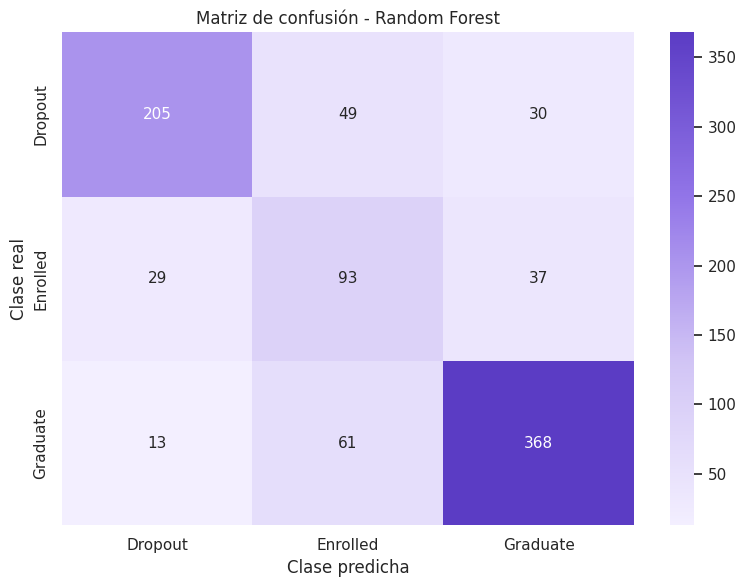

In [154]:
# Graficar matriz de confusión

# Paleta de colores morados
colores = ['#F3EFFF', '#D1C4F5', '#9275E8', '#5B3CC4']

cmap_grafico = LinearSegmentedColormap.from_list(
    'Morados',
    colores
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=pipeline.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=cmap_grafico,
    xticklabels=pipeline.classes_,
    yticklabels=pipeline.classes_
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


###**Análisis de la matriz de confusión**

---



La matriz muestra que el modelo clasificó correctamente 666 de los 885 registros evaluados, correspondientes a los valores de la diagonal:

Dropout: 205 registros clasificados correctamente. Se confundieron 49 con Enrolled y 30 con Graduate.

Enrolled: 93 registros clasificados correctamente. Se confundieron 29 con Dropout y 37 con Graduate.

Graduate: 368 registros clasificados correctamente. Se confundieron 13 con Dropout y 61 con Enrolled.

Se observa que la clase Graduate presenta la mayor cantidad de aciertos, mientras que Enrolled concentra las mayores dificultades de clasificación. Esto coincide con los resultados del reporte de clasificación anterior y evidencia que el modelo tiene dificultades para distinguir a los estudiantes matriculados de las otras categorías.

===========================================================================================================
###**15. Configuración de valores predeterminados y rangos de entrada**

---



Se generan valores predeterminados para las variables originales utilizando únicamente el conjunto de entrenamiento:

Variables categóricas: se asigna la moda, es decir, el valor más frecuente.

Variables numéricas: se utiliza la mediana.

Adicionalmente, se obtienen las opciones disponibles para los campos categóricos y los valores mínimos y máximos de las variables numéricas.

Finalmente, se realizan verificaciones para comprobar que todas las variables originales cuenten con valores predeterminados y que las variables categóricas tengan opciones definidas.

In [155]:

# Valores predeterminados basados en el conjunto de entrenamiento
defaults = {}

for col in original_features:
    if col in CATEGORICAL:
        defaults[col] = int(X_train[col].mode().iloc[0])
    else:
        defaults[col] = float(X_train[col].median())

# Opciones válidas para los campos categóricos
choices = {
    col: sorted(df[col].dropna().unique().tolist())
    for col in CATEGORICAL
}

# Rangos para los campos numéricos
ranges = {}

for col in NUMERICAL:
    if col in original_features:
        ranges[col] = {
            "min": float(X_train[col].min()),
            "max": float(X_train[col].max()),
            "default": defaults[col]
        }

print("Variables originales:", len(original_features))
print("Valores predeterminados:", len(defaults))
print("Variables categóricas con opciones:", len(choices))
print("Rangos numéricos disponibles:", len(ranges))

assert len(defaults) == len(original_features)
assert all(col in defaults for col in original_features)
assert all(col in choices for col in CATEGORICAL)

print("\n✅ Configuración de entradas preparada correctamente")

print("\nEjemplo de valores predeterminados:")
display(pd.Series(defaults).head(10).rename("Valor predeterminado"))


Variables originales: 36
Valores predeterminados: 36
Variables categóricas con opciones: 17
Rangos numéricos disponibles: 19

✅ Configuración de entradas preparada correctamente

Ejemplo de valores predeterminados:


,Valor predeterminado
Marital status,1.0
Application mode,1.0
Application order,1.0
Course,9500.0
Daytime/evening attendance,1.0
Previous qualification,1.0
Previous qualification (grade),133.1
Nacionality,1.0
Mother's qualification,1.0
Father's qualification,37.0



===========================================================================================================
###**16. Exportación del modelo entrenado**

---



Se construye un diccionario (bundle) que reúne los elementos necesarios para utilizar el modelo fuera del entorno de entrenamiento:

pipeline: preprocesador y modelo Random Forest entrenado.

original_features: nombres de las variables originales.

defaults: valores predeterminados para los campos de entrada.

ranges: rangos de las variables numéricas.

choices: opciones de las variables categóricas.

metrics: métricas obtenidas durante la evaluación.

classes: categorías que puede predecir el modelo.

Posteriormente, se utiliza joblib.dump() para exportar toda esta información en el archivo modelo_academico.joblib.

Finalmente, se verifica la exportación consultando la ruta, el tamaño del archivo y los elementos almacenados.

In [156]:
# Guardar el modelo
bundle = {
    "pipeline": pipeline,
    "original_features": original_features,
    "defaults": defaults,
    "ranges": ranges,
    "choices": choices,
    "metrics": metrics,
    "classes": list(pipeline.classes_)
}

ruta_modelo = Path("/content/modelo_academico.joblib")

joblib.dump(bundle, ruta_modelo)

print("✅ Modelo exportado correctamente")
print("Ruta:", ruta_modelo)
print("Tamaño:", round(ruta_modelo.stat().st_size / (1024 ** 2), 2), "MB")
print("Elementos guardados:", list(bundle.keys()))

✅ Modelo exportado correctamente
Ruta: /content/modelo_academico.joblib
Tamaño: 24.18 MB
Elementos guardados: ['pipeline', 'original_features', 'defaults', 'ranges', 'choices', 'metrics', 'classes']


In [157]:
# Verificar la descarga
bundle_test = joblib.load("/content/modelo_academico.joblib")

check_is_fitted(bundle_test["pipeline"].named_steps["model"])

print("✅ Archivo cargado y modelo verificado")
print("Variables originales:", len(bundle_test["original_features"]))
print("Clases:", bundle_test["classes"])
print(
    "Número de árboles:",
    len(bundle_test["pipeline"].named_steps["model"].estimators_)
)
print("Métricas recuperadas:", bundle_test["metrics"])

✅ Archivo cargado y modelo verificado
Variables originales: 36
Clases: ['Dropout', 'Enrolled', 'Graduate']
Número de árboles: 500
Métricas recuperadas: {'Accuracy': 0.752542372881356, 'F1 macro': 0.7083882814594195, 'F1 weighted': 0.7592291388864715, 'Balanced accuracy': np.float64(0.7131052772710712), 'Log loss': 0.6203681360657035}


===========================================================================================================
###**17. Prueba de predicción del modelo exportado**


---



Se construye un registro de prueba utilizando los valores predeterminados almacenados en bundle_test, correspondientes a las variables originales del conjunto de entrenamiento.

Posteriormente, se generan las cinco características derivadas mediante add_engineered_features() y se recupera el pipeline desde el archivo exportado.

Con estos datos, se ejecuta la predicción de la clase objetivo y se calculan las probabilidades estimadas para cada categoría.

Finalmente, se muestran la clase predicha, las probabilidades por categoría y las dimensiones de los datos antes y después de la ingeniería de características.

In [158]:
# Testing de prediccion


# Crear un registro de prueba con los valores predeterminados
entrada_prueba = pd.DataFrame([
    {
        col: bundle_test["defaults"][col]
        for col in bundle_test["original_features"]
    }
])

# Generar las cinco variables derivadas
entrada_transformada = add_engineered_features(entrada_prueba)

# Predecir usando el pipeline recuperado del archivo
modelo_cargado = bundle_test["pipeline"]

prediccion = modelo_cargado.predict(entrada_transformada)[0]
probabilidades = modelo_cargado.predict_proba(entrada_transformada)[0]

print("✅ Prueba de predicción completada")
print("Predicción:", prediccion)
print("\nProbabilidades por clase:")

for clase, probabilidad in zip(bundle_test["classes"], probabilidades):
    print(f"{clase:<12}: {probabilidad:.2%}")

print("\nForma de los datos originales:", entrada_prueba.shape)
print("Forma de los datos transformados:", entrada_transformada.shape)


✅ Prueba de predicción completada
Predicción: Enrolled

Probabilidades por clase:
Dropout     : 11.37%
Enrolled    : 56.11%
Graduate    : 32.52%

Forma de los datos originales: (1, 36)
Forma de los datos transformados: (1, 41)


===========================================================================================================
###**18. Descarga de los archivos del modelo**

---

Se descargan los archivos necesarios para ejecutar el modelo en el entorno local:

modelo_academico.joblib: contiene el pipeline entrenado, las configuraciones de entrada y las métricas de evaluación.

feature_engineering.py: contiene la función encargada de generar las cinco características derivadas utilizadas durante el entrenamiento y la predicción.

Ambos archivos se utilizarán posteriormente en la aplicación desarrollada con Streamlit.

In [161]:
# Descargar el modelo

from google.colab import files

files.download("/content/modelo_academico.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [162]:
# Descargar la ingenieria de caracteristicas
files.download("/content/feature_engineering.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>